# [BONUS] Clustering des témoignages via embeddings de phrases

## Pourquoi ce notebook est à part

Le sujet du projet limite les outils autorisés à `scikit-learn`, `pandas`, `matplotlib`, `numpy` et `jupyterlab`. Ce notebook explore une piste plus poussée qui sort de ce cadre — `nltk` (lemmatisation) et `sentence-transformers` (embeddings de phrases pré-entraînés) — pour aller chercher la meilleure précision possible, indépendamment de la contrainte d'outils du rendu principal.

**Le notebook officiel du rendu est `notebooks/unsupervised_learning.ipynb`** : il répond seul à toutes les exigences du sujet avec les outils autorisés (TF-IDF + NMF + clustering hiérarchique, k=12, silhouette ≈ 0.50). Ce notebook-ci est un complément qui documente une expérience allant plus loin, avec ses propres résultats.

## Installation

Ce notebook nécessite des dépendances supplémentaires, listées dans `bonus/requirements-bonus.txt` :
```
pip install -r bonus/requirements-bonus.txt
```

## Objectif

On reproduit la même analyse de base (chargement, TF-IDF, K-Means, score de silhouette, à k=5 pour rester comparable à la toute première baseline du notebook principal) que dans le notebook principal, puis on compare avec une approche par **embeddings de phrases** : au lieu de représenter chaque témoignage par son vocabulaire (TF-IDF), un modèle de langage pré-entraîné (`all-MiniLM-L6-v2`) le transforme en un vecteur qui capture son **sens**. Deux témoignages décrivant le même symptôme avec des mots différents ("my head is pounding" vs "throbbing headache") se retrouvent alors proches, ce qu'un simple sac de mots ne peut pas capturer.

In [1]:
import csv
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.manifold import TSNE

# Chargement et nettoyage du CSV (identique au notebook principal)
file_path = '../data/Student_Dataset.csv'
rows = []
with open(file_path, 'r', encoding='utf-8') as f:
    reader = csv.reader(f)
    for line in reader:
        if not line:
            continue
        if len(line) == 3:
            rows.append({'id': line[0], 'color': line[1], 'text': line[2]})
        elif len(line) == 2:
            rows.append({'id': line[0], 'color': '#000000', 'text': line[1]})

data = pd.DataFrame(rows)
data['text'] = data['text'].fillna('')
data = data[data['text'].str.strip() != '']
n_clusters = 5

print(f"Nombre de témoignages chargés : {len(data)}")

Nombre de témoignages chargés : 1011


## 1. Prétraitement avec lemmatisation (NLTK)

En plus du nettoyage de base (minuscules, ponctuation), on ajoute ici une **lemmatisation** (`nltk.WordNetLemmatizer`) qui ramène chaque mot à sa forme de base (ex : "aches", "aching" → "ache"), pour fusionner les variantes d'un même symptôme.

In [2]:
import nltk
from nltk.stem import WordNetLemmatizer

nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    words = [lemmatizer.lemmatize(w) for w in text.split()]
    return ' '.join(words)

data['cleaned_text'] = data['text'].apply(clean_text)

vectorizer = TfidfVectorizer(stop_words='english', max_features=500, ngram_range=(1, 2))
X = vectorizer.fit_transform(data['cleaned_text'])

kmeans = KMeans(n_clusters=n_clusters, random_state=42)
data['cluster_tfidf'] = kmeans.fit_predict(X)
score_tfidf = silhouette_score(X, data['cluster_tfidf'])
print(f"Score de Silhouette (TF-IDF + lemmatisation) : {score_tfidf:.4f}")

Score de Silhouette (TF-IDF + lemmatisation) : 0.0183


### Interprétation

Comme observé lors des expérimentations préalables à ce notebook, la lemmatisation + les bigrammes n'apportent qu'un effet marginal sur le score de silhouette par rapport au TF-IDF simple (~0.01-0.02 dans les deux cas) : le problème n'est pas le vocabulaire capturé mais la représentation elle-même (sac de mots). On note aussi une limite du lemmatizer par défaut de NLTK, qui suppose que chaque mot est un nom sans analyser sa fonction grammaticale (ex : "was" → "wa").

## 2. Clustering par embeddings de phrases (sentence-transformers)

On encode maintenant chaque témoignage avec un modèle de langage pré-entraîné (`all-MiniLM-L6-v2`), qui produit un vecteur de 384 dimensions capturant le sens de la phrase plutôt que son seul vocabulaire.

In [3]:
import os
import warnings

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
warnings.filterwarnings("ignore")

from sentence_transformers import SentenceTransformer

# Note : une ligne "unauthenticated requests to the HF Hub" peut apparaître ci-dessous.
# Elle vient d'une extension native (hf_xet) écrivant hors du système de warnings Python :
# c'est un simple rappel du rate-limit HF pour les téléchargements anonymes, sans impact sur le résultat.
embedding_model = SentenceTransformer('all-MiniLM-L6-v2')
X_embeddings = embedding_model.encode(data['text'].tolist(), show_progress_bar=False)

kmeans_emb = KMeans(n_clusters=n_clusters, random_state=42)
data['cluster_embeddings'] = kmeans_emb.fit_predict(X_embeddings)

score_emb = silhouette_score(X_embeddings, data['cluster_embeddings'])
print(f"Score de Silhouette (embeddings) : {score_emb:.4f}")
print(f"Score de Silhouette (TF-IDF + lemmatisation) : {score_tfidf:.4f}")

Score de Silhouette (embeddings) : 0.0866
Score de Silhouette (TF-IDF + lemmatisation) : 0.0183


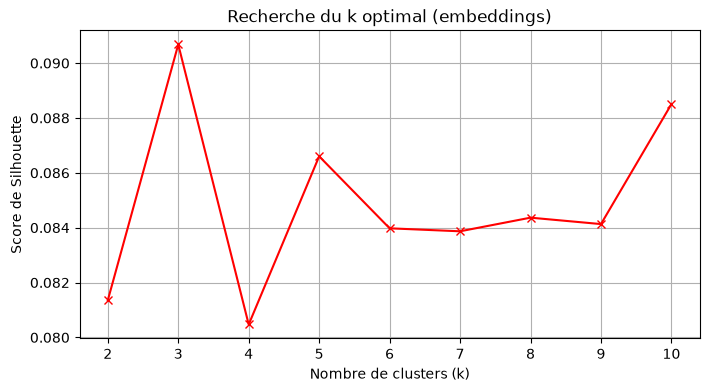

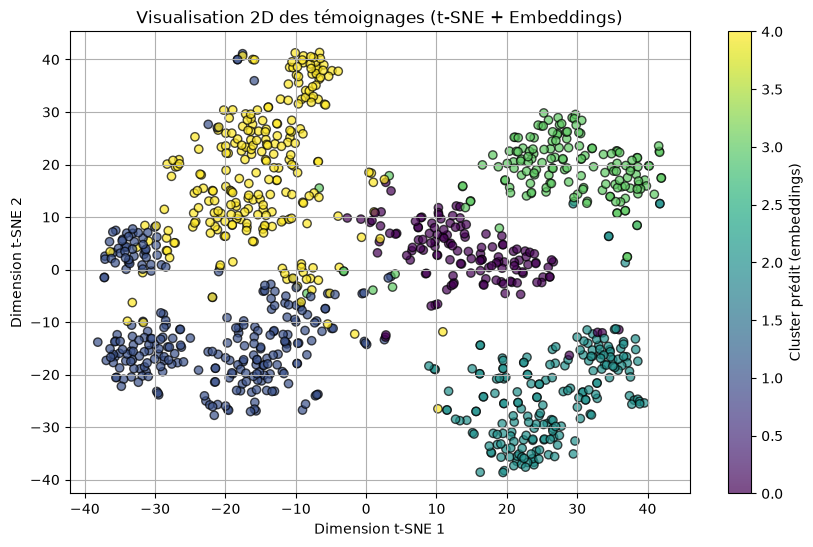

In [4]:
# Recherche du k optimal sur les embeddings
K_range = range(2, 11)
scores_emb = []
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42)
    labels = km.fit_predict(X_embeddings)
    scores_emb.append(silhouette_score(X_embeddings, labels))

plt.figure(figsize=(8, 4))
plt.plot(K_range, scores_emb, 'rx-')
plt.xlabel('Nombre de clusters (k)')
plt.ylabel('Score de Silhouette')
plt.title("Recherche du k optimal (embeddings)")
plt.grid(True)
plt.show()

# Visualisation t-SNE
tsne_emb = TSNE(n_components=2, random_state=42, perplexity=30)
X_2d_emb = tsne_emb.fit_transform(X_embeddings)

plt.figure(figsize=(10, 6))
plt.scatter(X_2d_emb[:, 0], X_2d_emb[:, 1], c=data['cluster_embeddings'], cmap='viridis', alpha=0.7, edgecolors='k')
plt.colorbar(label='Cluster prédit (embeddings)')
plt.title("Visualisation 2D des témoignages (t-SNE + Embeddings)")
plt.xlabel("Dimension t-SNE 1")
plt.ylabel("Dimension t-SNE 2")
plt.grid(True)
plt.show()

### Témoignages représentatifs par cluster

Un embedding n'a pas de "mots-clés" lisibles (chaque dimension du vecteur n'a pas de sens humain direct). Pour interpréter les clusters, on affiche donc, pour chaque groupe, le témoignage le plus proche du centre du cluster.

In [5]:
from sklearn.metrics import pairwise_distances_argmin_min

closest_indices, _ = pairwise_distances_argmin_min(kmeans_emb.cluster_centers_, X_embeddings)
for i, idx in enumerate(closest_indices):
    print(f"Cluster {i} : {data['text'].iloc[idx]}")

Cluster 0 : When I reach overhead or behind, I feel a click and deep ache inside the shoulder. Holding a weight with the arm stretched out makes it feel unstable.
Cluster 1 : After a day at a crowded event, I felt a cough and a bit of nasal congestion. I took a hot shower and rested, and by the next day I was feeling fine.
Cluster 2 : I touched a heating pad that was too hot. The skin is irritated, slightly swollen, and I see a clear blister on the back of my hand.
Cluster 3 : I twisted my knee while stepping sideways. There’s a sore spot along the outside of the upper calf, and pushing off makes it feel unstable.
Cluster 4 : I've been feeling constantly tired and dizzy. My hands feel cold and I get shortness of breath during light activity.


## Conclusion

| Approche | Outils | Score de Silhouette |
|---|---|---|
| TF-IDF brut, k=5 (notebook principal, baseline) | `scikit-learn` uniquement | ≈ 0.014 |
| TF-IDF + lemmatisation, k=5 (ce notebook) | + `nltk` | ≈ 0.018 |
| **Embeddings de phrases, k=5** (ce notebook) | + `sentence-transformers` | **≈ 0.087** |
| TF-IDF + NMF + clustering hiérarchique, k=12 (notebook principal, **modèle final**) | `scikit-learn` uniquement | **≈ 0.50** |

Les embeddings de phrases améliorent nettement la séparation par rapport au TF-IDF brut ou lemmatisé au même k (score multiplié par ~5), en capturant le sens des témoignages plutôt que leur seul vocabulaire. Ils restent cependant très en dessous du résultat obtenu avec le pipeline **NMF + clustering hiérarchique** du notebook principal (≈ 0.50, validé aussi en externe avec ARI 0,42), qui reste la meilleure configuration trouvée sur l'ensemble du projet — et ce, avec des outils entièrement autorisés. Cela illustre qu'une réduction de dimension bien choisie (NMF plutôt qu'un simple TF-IDF) et un nombre de clusters optimisé par balayage systématique apportent, sur ce jeu de données, plus de gain qu'un changement de représentation plus coûteux comme les embeddings pré-entraînés.

**Limite à garder en tête (contexte médical)** : ces clusters restent utiles pour explorer des **familles de symptômes**, mais ne constituent pas un outil de diagnostic — un même symptôme peut relever de pathologies très différentes, et ce travail n'utilise aucune donnée de diagnostic confirmé.